# Bleien 7-m time--frequency data and a candidate RFI mask

Data: example Galactic-survey data from the Bleien Observatory 7-m telescope (frequency axis as stored in the file; see below), distributed with the SEEK package
(<https://people.phys.ethz.ch/~ipa/cosmo/bgs_example_data/>). Relevant references: Chang et al. 2016 (arXiv:1607.07451) for the instrument and
Akeret et al. 2017 (arXiv:1607.07443) for HIDE & SEEK.

The notebook produces three figures: (1) an annotated spectrogram, (2) spectrogram + illustrative candidate RFI mask, (3) a zoom on the strongest persistent band.


In [1]:
import warnings
from io import BytesIO
from pathlib import Path

import numpy as np
import h5py
import requests
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Patch
from scipy.ndimage import median_filter, label

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 140, "savefig.dpi": 300, "font.size": 11,
    "axes.titlesize": 12, "axes.labelsize": 11,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 9,
})

In [2]:
# -----------------------------------------------------------------------------
# Download and load
# -----------------------------------------------------------------------------
URL = ("https://people.phys.ethz.ch/~ipa/cosmo/bgs_example_data/2016/03/21/"
       "HIMap_RSG7M_A1_24_MP_PXX_Z0_C0-M9703A_DPUA_20160321_074402.h5")

response = requests.get(URL, timeout=90)
response.raise_for_status()

with h5py.File(BytesIO(response.content), "r") as fp:
    print("File keys:", list(fp.keys()))
    tod = fp["P/Phase1"][()].astype(float)
    time = fp["TIME"][()].astype(float)
    freq_file = fp["FREQUENCY"][()].astype(float) if "FREQUENCY" in fp else None

print("tod shape:", tod.shape)

File keys: ['FREQUENCY', 'P', 'P2', 'TIME']
tod shape: (9000, 120)


In [3]:
# -----------------------------------------------------------------------------
# Axes: use the frequency/time axes stored in the file; do NOT assume them
# -----------------------------------------------------------------------------
n_freq, n_time = tod.shape

freq_axis = None
if freq_file is not None:
    f = np.ravel(freq_file)
    if f.size == n_freq:
        freq_axis = f / 1e6 if np.nanmax(f) > 1e6 else f   # Hz -> MHz if needed
    else:
        print(f"WARNING: FREQUENCY has {f.size} values but data have {n_freq} channels.")
if freq_axis is None:
    print("WARNING: no usable FREQUENCY array; falling back to a linear 990-1260 MHz axis. VERIFY against the source paper.")
    freq_axis = np.linspace(990.0, 1260.0, n_freq)

# Make the frequency axis ascending
if freq_axis[0] > freq_axis[-1]:
    freq_axis = freq_axis[::-1]
    tod = tod[::-1, :]

time = np.ravel(time)
if time.size != n_time:
    print(f"WARNING: TIME has {time.size} values but data have {n_time} time samples.")
    time = np.arange(n_time, dtype=float)
t_rel = time - time[0]

print(f"freq: {freq_axis[0]:.3f} .. {freq_axis[-1]:.3f} MHz, step {np.median(np.diff(freq_axis))*1e3:.2f} kHz")
print("time[:5]   :", time[:5])
print("t_rel step :", np.median(np.diff(t_rel)), "(units as stored in the file -- CHECK; assumed seconds in labels)")
print(f"data min/max: {np.nanmin(tod):.3e} / {np.nanmax(tod):.3e}")

TIME_LABEL = "Time since start of observation [s]"
FREQ_LABEL = "Frequency [MHz]"

freq: 0.000 .. 439.431 MHz, step 48.83 kHz
time[:5]   : [ 0.  6. 12. 19. 25.]
t_rel step : 6.0 (units as stored in the file -- CHECK; assumed seconds in labels)
data min/max: 2.877e+09 / 3.140e+14


In [4]:
# -----------------------------------------------------------------------------
# Simple candidate RFI mask (illustrative only)
#   1. persistent channels: channel median (in log10) after removing a smooth bandpass
#   2. transient pixels   : pixel value after removing each channel's own median
# Both use robust (median/MAD) scores. Band-edge channels are excluded.
# -----------------------------------------------------------------------------
CHANNEL_THRESHOLD = 6.0      # robust sigma
PIXEL_THRESHOLD   = 8.0      # robust sigma
BANDPASS_WIDTH    = 301      # channels in the running median used to flatten the bandpass
EDGE_FRACTION     = 0.01     # fraction of channels always ignored at each band edge
ROLLOFF_DEX       = 0.5      # also ignore channels whose median level is this many dex below the typical level (filter roll-off)

def robust_sigma(x):
    x = x[np.isfinite(x)]
    return 1.4826 * np.median(np.abs(x - np.median(x)))

log_data = np.log10(np.where(tod > 0, tod, np.nan))

row_med = np.nanmedian(log_data, axis=1)
row_med = np.where(np.isfinite(row_med), row_med, np.nanmedian(row_med))
row_res = row_med - median_filter(row_med, size=BANDPASS_WIDTH, mode="nearest")
row_score = (row_res - np.median(row_res)) / robust_sigma(row_res)

pix_res = log_data - row_med[:, None]
pixel_score = (pix_res - np.nanmedian(pix_res)) / robust_sigma(pix_res)

edge = int(EDGE_FRACTION * n_freq)
valid = np.ones(n_freq, dtype=bool)
valid[:edge] = False
valid[n_freq - edge:] = False
valid &= row_med > (np.median(row_med) - ROLLOFF_DEX)   # drop roll-off regions at the band ends
print(f"usable band (roll-off excluded): {freq_axis[valid].min():.1f} .. {freq_axis[valid].max():.1f} MHz "
      f"({valid.sum()} / {n_freq} channels)")

candidate_channel_mask = (row_score > CHANNEL_THRESHOLD) & valid
candidate_pixel_mask = (np.nan_to_num(pixel_score, nan=0.0) > PIXEL_THRESHOLD) & valid[:, None]
candidate_mask = candidate_pixel_mask | candidate_channel_mask[:, None]

print(f"flagged channels (persistent): {candidate_channel_mask.sum()} / {n_freq}")
print(f"flagged pixels (total)       : {candidate_mask.mean():.3%}")

# Group adjacent flagged channels into bands and rank them
lab, nlab = label(candidate_channel_mask)
bands = []
for i in range(1, nlab + 1):
    idx = np.where(lab == i)[0]
    k = idx[np.argmax(row_score[idx])]
    bands.append(dict(fmin=freq_axis[idx].min(), fmax=freq_axis[idx].max(),
                      fpeak=freq_axis[k], score=row_score[k], n=idx.size))
bands.sort(key=lambda b: -b["score"])

print("\nStrongest persistent bands (edges excluded):")
for b in bands[:8]:
    print(f"  {b['fmin']:8.2f} - {b['fmax']:8.2f} MHz  peak {b['fpeak']:8.2f} MHz  "
          f"score {b['score']:6.1f}  ({b['n']} channels)")

if bands:
    target_freq = bands[0]["fpeak"]
else:
    target_freq = freq_axis[np.argmax(np.where(valid, row_score, -np.inf))]
    print("No band above threshold; using the highest channel score for the zoom.")

usable band (roll-off excluded): 24.8 .. 401.1 MHz (7707 / 9000 channels)
flagged channels (persistent): 425 / 9000
flagged pixels (total)       : 9.287%

Strongest persistent bands (edges excluded):
    128.13 -   131.89 MHz  peak   129.99 MHz  score  551.6  (78 channels)
     67.83 -    72.12 MHz  peak    70.07 MHz  score  214.7  (89 channels)
    179.65 -   180.33 MHz  peak   179.99 MHz  score  183.3  (15 channels)
    153.67 -   154.36 MHz  peak   154.01 MHz  score  145.0  (15 channels)
    100.64 -   101.32 MHz  peak   100.98 MHz  score  141.3  (15 channels)
    126.33 -   127.60 MHz  peak   127.01 MHz  score  104.1  (27 channels)
    158.75 -   159.19 MHz  peak   158.95 MHz  score   95.3  (10 channels)
    147.76 -   148.25 MHz  peak   148.01 MHz  score   87.0  (11 channels)


In [5]:
# -----------------------------------------------------------------------------
# Display helpers: bin along frequency so that thin structures are not lost
# when ~9000 channels are drawn on a few hundred pixel rows.
#   - data: mean of log10 intensity per bin
#   - mask: logical OR (max-pool) per bin
# -----------------------------------------------------------------------------
N_DISP = 600

def bin_rows(a, n, reducer):
    return np.array([reducer(c, axis=0) for c in np.array_split(a, n, axis=0)])

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    log_disp = bin_rows(log_data, N_DISP, np.nanmean)
mask_disp = bin_rows(candidate_mask, N_DISP, np.any)
excl_disp = bin_rows(~valid, N_DISP, np.all)      # channels excluded from flagging (band edges / roll-off)

# Flag significance (robust sigma): pixel flags use the pixel score, persistent-channel flags use the channel score.
# Shading by significance keeps weak and strong flags distinguishable (a binary black mask hides that).
strength = np.where(candidate_pixel_mask, np.nan_to_num(pixel_score, nan=0.0), 0.0)
strength = np.maximum(strength, np.where(candidate_channel_mask, row_score, 0.0)[:, None])
strength_disp = bin_rows(strength, N_DISP, np.max)
strength_disp = np.ma.masked_where(strength_disp <= 0, strength_disp)
s_lo = min(CHANNEL_THRESHOLD, PIXEL_THRESHOLD)
s_hi = np.percentile(strength[strength > 0], 98)       # saturate the colour scale at the strongest ~2% of flags
SCORE_NORM = LogNorm(vmin=s_lo, vmax=max(s_hi, 2 * s_lo))

vmin, vmax = np.nanpercentile(log_disp, [1, 99.8])
extent = (t_rel[0], t_rel[-1], freq_axis[0], freq_axis[-1])
CBAR_LABEL = r"$\log_{10}$ intensity (arb. units)"

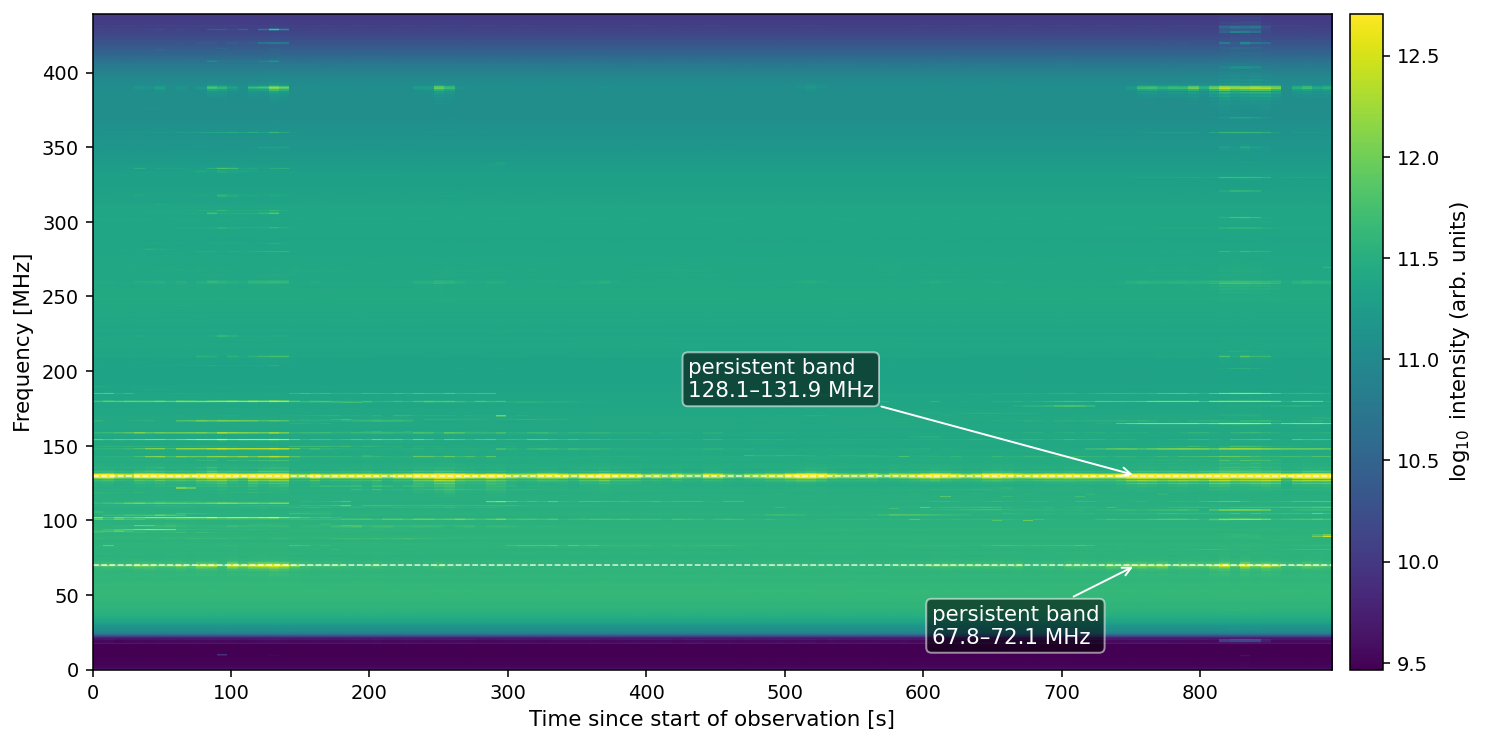

In [6]:
# -----------------------------------------------------------------------------
# Figure 1: annotated spectrogram (annotations are derived from the data)
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10.5, 5.2), constrained_layout=True)
im = ax.imshow(log_disp, aspect="auto", extent=extent, origin="lower",
               cmap="viridis", vmin=vmin, vmax=vmax, interpolation="nearest")
cbar = fig.colorbar(im, ax=ax, pad=0.015)
cbar.set_label(CBAR_LABEL)

ax.set_xlabel(TIME_LABEL)
ax.set_ylabel(FREQ_LABEL)

span = freq_axis[-1] - freq_axis[0]
for j, b in enumerate(bands[:2]):
    ax.axhline(b["fpeak"], color="white", lw=0.8, ls="--", alpha=0.8)
    ytxt = b["fpeak"] + (0.12 if j == 0 else -0.12) * span
    ytxt = min(max(ytxt, freq_axis[0] + 0.04 * span), freq_axis[-1] - 0.06 * span)
    ax.annotate(f"persistent band\n{b['fmin']:.1f}\u2013{b['fmax']:.1f} MHz",
                xy=(t_rel[int(0.80 * n_time)], b["fpeak"]),
                xytext=(t_rel[int((0.40 + 0.2 * j) * n_time)], ytxt),
                arrowprops=dict(arrowstyle="->", lw=1.0, color="white"),
                color="white",
                bbox=dict(boxstyle="round,pad=0.25", fc="black", ec="white", alpha=0.55))

fig.savefig(FIG_DIR / "bleien_rfi_annotated_spectrogram.png", bbox_inches="tight")
fig.savefig(FIG_DIR / "bleien_rfi_annotated_spectrogram.pdf", bbox_inches="tight")
plt.show()

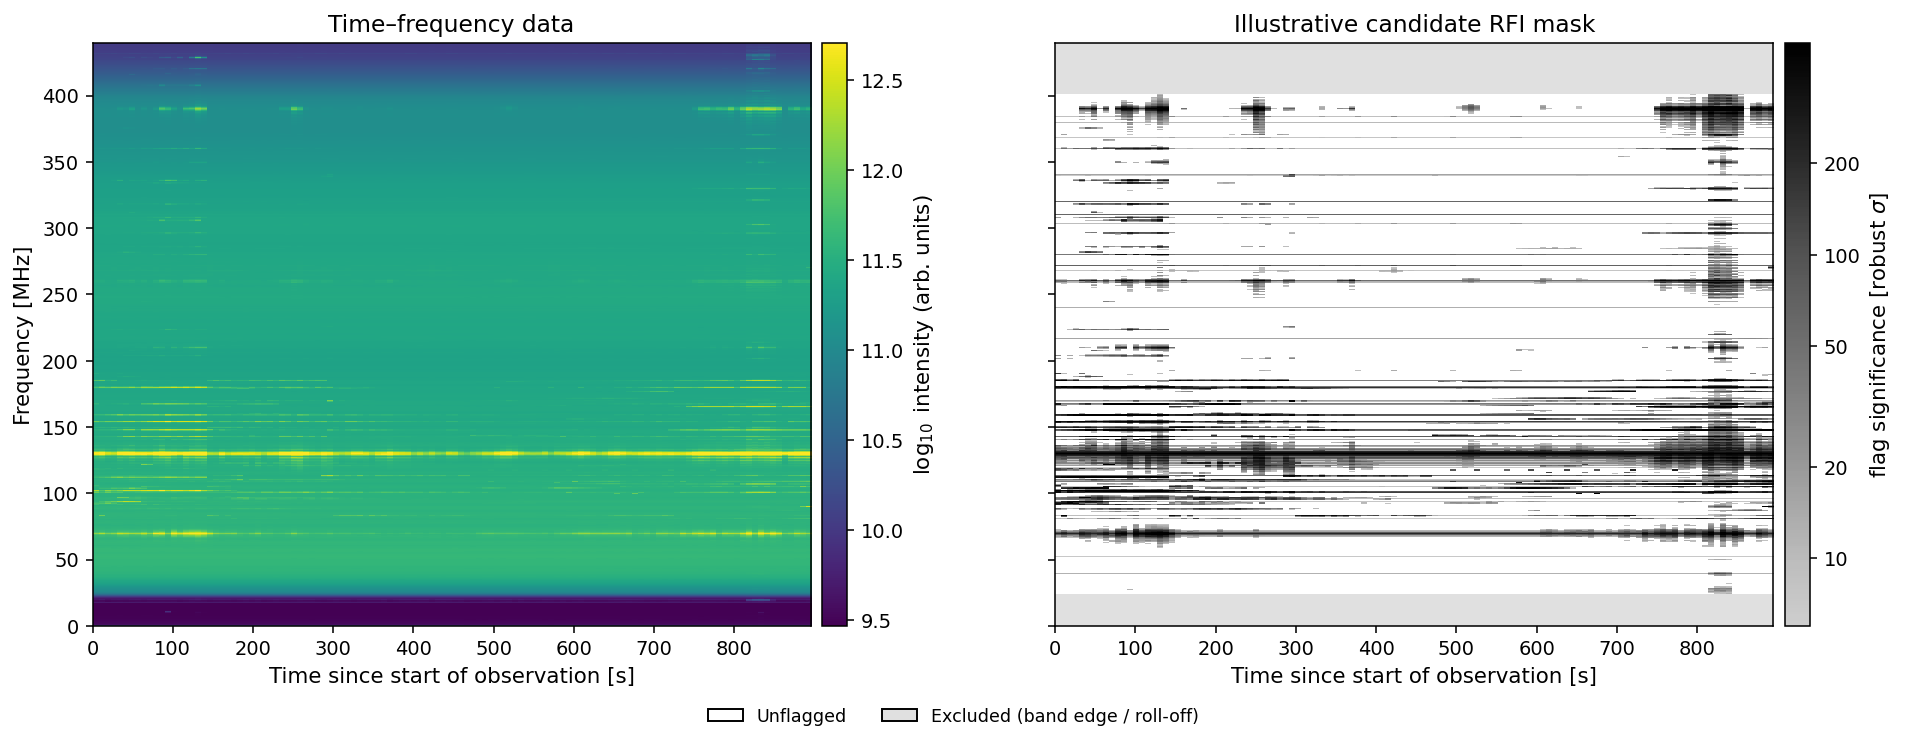

In [7]:
# -----------------------------------------------------------------------------
# Figure 2 (paper Figure 1): spectrogram + illustrative candidate RFI mask
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=(13.5, 5.2), constrained_layout=True)
gs = fig.add_gridspec(1, 5, width_ratios=[1, 0.035, 0.14, 1, 0.035])
ax0 = fig.add_subplot(gs[0, 0])
cax = fig.add_subplot(gs[0, 1])
ax1 = fig.add_subplot(gs[0, 3], sharex=ax0, sharey=ax0)
cax1 = fig.add_subplot(gs[0, 4])      # vertical colourbar for the mask shading

im0 = ax0.imshow(log_disp, aspect="auto", extent=extent, origin="lower",
                 cmap="viridis", vmin=vmin, vmax=vmax, interpolation="nearest")
ax0.set_title("Time–frequency data")
ax0.set_xlabel(TIME_LABEL)
ax0.set_ylabel(FREQ_LABEL)
cb = fig.colorbar(im0, cax=cax)
cb.set_label(CBAR_LABEL)

# background: white = unflagged, grey = excluded from flagging
ax1.imshow(excl_disp[:, None].astype(int), aspect="auto", extent=extent, origin="lower",
           cmap=ListedColormap(["white", "0.88"]), vmin=0, vmax=1, interpolation="nearest")
# overlay: flagged pixels shaded by significance (light = weak, black = strong)
flag_cmap = plt.get_cmap("Greys")(np.linspace(0.3, 1.0, 256))
im1 = ax1.imshow(strength_disp, aspect="auto", extent=extent, origin="lower",
                 cmap=ListedColormap(flag_cmap), norm=SCORE_NORM, interpolation="nearest")
ax1.set_title("Illustrative candidate RFI mask")
ax1.set_xlabel(TIME_LABEL)
plt.setp(ax1.get_yticklabels(), visible=False)
cb1 = fig.colorbar(im1, cax=cax1)
cb1.set_label(r"flag significance [robust $\sigma$]")
ticks = [t for t in (10, 20, 50, 100, 200, 500) if SCORE_NORM.vmin <= t <= SCORE_NORM.vmax]
cb1.set_ticks(ticks)
cb1.set_ticklabels([str(t) for t in ticks])
cb1.ax.minorticks_off()
fig.legend(handles=[Patch(facecolor="white", edgecolor="k", label="Unflagged"),
                    Patch(facecolor="0.88", edgecolor="k", label="Excluded (band edge / roll-off)")],
           loc="outside lower center", ncol=2, frameon=False)   # below the panels, never covers data

fig.savefig(FIG_DIR / "bleien_rfi_spectrogram_and_candidate_mask.png", bbox_inches="tight")
fig.savefig(FIG_DIR / "bleien_rfi_spectrogram_and_candidate_mask.pdf", bbox_inches="tight")
plt.show()

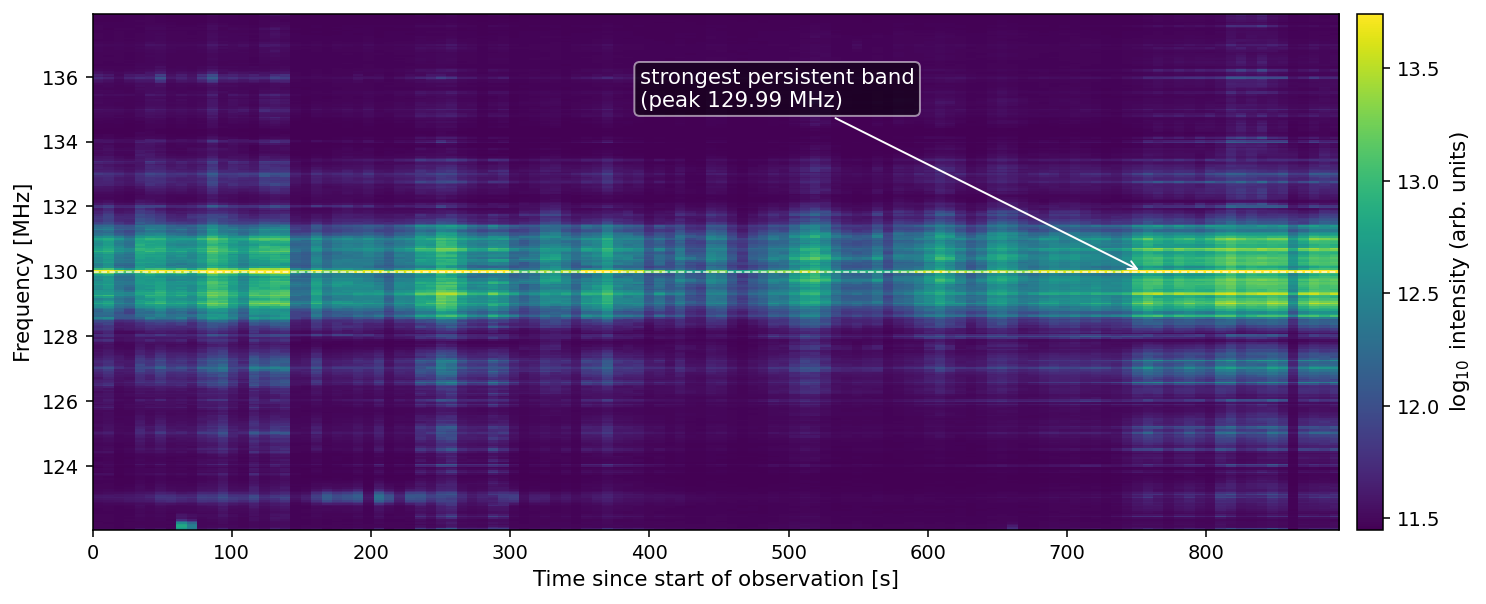

In [8]:
# -----------------------------------------------------------------------------
# Figure 3: zoom on the strongest persistent band (full channel resolution)
# -----------------------------------------------------------------------------
HALF_WIDTH_MHZ = 8.0
f_lo, f_hi = target_freq - HALF_WIDTH_MHZ, target_freq + HALF_WIDTH_MHZ
rows = (freq_axis >= f_lo) & (freq_axis <= f_hi)
zoom = log_data[rows, :]
zf = freq_axis[rows]

fig, ax = plt.subplots(figsize=(10.5, 4.2), constrained_layout=True)
im = ax.imshow(zoom, aspect="auto",
               extent=(t_rel[0], t_rel[-1], zf[0], zf[-1]), origin="lower",
               cmap="viridis", interpolation="nearest",
               vmin=np.nanpercentile(zoom, 1), vmax=np.nanpercentile(zoom, 99.8))
cbar = fig.colorbar(im, ax=ax, pad=0.015)
cbar.set_label(CBAR_LABEL)
ax.set_xlabel(TIME_LABEL)
ax.set_ylabel(FREQ_LABEL)
ax.axhline(target_freq, color="white", lw=0.8, ls="--", alpha=0.8)
ax.annotate(f"strongest persistent band\n(peak {target_freq:.2f} MHz)",
            xy=(t_rel[int(0.80 * n_time)], target_freq),
            xytext=(t_rel[int(0.35 * n_time)], zf[-1] - 0.18 * (zf[-1] - zf[0])),
            arrowprops=dict(arrowstyle="->", lw=1.0, color="white"), color="white",
            bbox=dict(boxstyle="round,pad=0.25", fc="black", ec="white", alpha=0.55))

fig.savefig(FIG_DIR / "bleien_rfi_zoomed_band.png", bbox_inches="tight")
fig.savefig(FIG_DIR / "bleien_rfi_zoomed_band.pdf", bbox_inches="tight")
plt.show()